# Comparaison des estimateurs du score - mémorisation et temps de calcul

Comparaison ici des différents estimateurs que Stuart et al. utilisent :
- L'estimateur du score empirique explicite
- L'estimateur du score empirique explicite avec une régularisation ridge (Tikhonov)
- L'estimateur du score issu d'un réseau de neurones
- L'estimateur du score issu d'un réseau de neurones régularisé (perte de Tikhonov)
- L'estimateur que j'ai trouvé issu de la Cross Validation (explicite), en version LOO, implémenté deux fois :
  - version naïve (on recalcule les $N$ mélanges $p^{D_{-k}}$ séparément, coût $O(N^2)$ par évaluation)
  - version optimisée (mutualisation des sommes globales, coût $O(N)$)
- Et l'estimateur dans le cas K-Fold ($K=5$)

Je compare les taux de mémorisation selon les méthodes (avec ou sans régularisation) et les temps d'exécution de ces différents estimateurs.

Cadre expérimental :
- $N = 20$ points i.i.d. de $p_0 = \mathcal N(0, I_2)$ 
- processus VE avec $g(t) = 10t$ et $T = 1$ 
- génération par l'ODE reverse déterministe, initialisée en $x(T) \sim \mathcal N(0, \sigma^2(T) I_2)$ 
- mémorisation mesurée par la fraction d'échantillons générés à distance $< \tau$ d'une donnée d'entraînement ($\tau = 10^{-2}$ pour les scores explicites dans l'article, $\tau = 10^{-1}$ pour les réseaux de neurones  on donne les deux)

## Imports et paramètres globaux

In [351]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import copy
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d

np.set_printoptions(precision=5, suppress=True)
plt.rcParams["figure.dpi"] = 110

SEED_DATA = 0     #graine du dataset
SEED_INIT = 5     #graine des conditions initiales x(T)
N, d = 20, 2      #20 points en dim 2
N_GEN = 500       #nombre d'échantillons générés (pour les histogrammes / taux)
N_SHOW = 12       #nombre de trajectoires affichées
TAU_EXPLICITE, TAU_NN = 1e-2, 1e-1

## 1. Jeu de données

On tire $N=20$ points de $\mathcal N(0, I_2)$ et on construit le diagramme de Voronoï associé, qui sert de fond à toutes les figures.

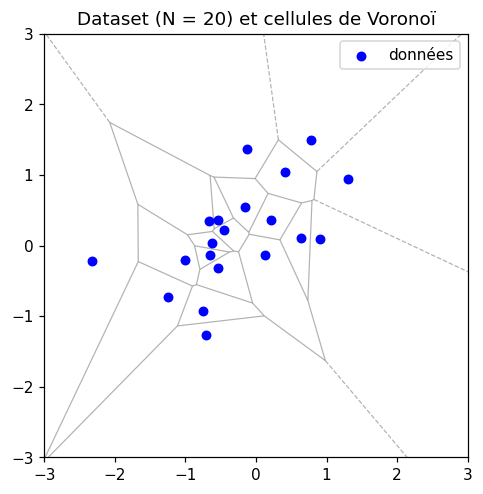

distance min entre deux points : 0.1299
moyenne des distances au plus proche voisin : 0.4092


In [352]:
X = np.random.default_rng(SEED_DATA).standard_normal((N, d))
vor = Voronoi(X)

fig, ax = plt.subplots(figsize=(5, 5))
voronoi_plot_2d(vor, ax=ax, show_points=False, show_vertices=False,
                line_colors="grey", line_width=0.8, line_alpha=0.6)
ax.scatter(X[:, 0], X[:, 1], c="blue", s=30, zorder=3, label="données")
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.legend()
ax.set_title("Dataset (N = 20) et cellules de Voronoï")
plt.show()

dists = np.sqrt(((X[:, None] - X[None]) ** 2).sum(-1)) + np.diag(np.full(N, np.inf))
print(f"distance min entre deux points : {dists.min():.4f}")
print(f"moyenne des distances au plus proche voisin : {dists.min(1).mean():.4f}")

## 2. Processus forward, ODE reverse et changement de temps

**Forward (VE)** : $\beta = 0$, $g(t) = 10t$, donc $m(t) = 1$ et
$$\sigma^2(t) = \int_0^t g(s)\,ds = 5t^2 \qquad \sigma(T) = \sqrt 5 $$

**ODE reverse** ($\alpha_1 = 1/2$, $\alpha_2 = 0$) :
$$\frac{dx}{dt} = -\frac{g(t)}{2}\, s(x,t)$$

**Changement de temps** : on pose $\sigma = e^{-s}$, $s = -\ln \sigma(t)$. Comme $\sigma(t) = \sqrt5\, t$, on a $dt/ds = -t$ et
$$\frac{dy}{ds} = \frac{dx}{dt}\frac{dt}{ds} = \frac{g(t)}{2}\, t\, s(y,t) = 5t^2\, s(y,t) = \sigma^2\, s(y,\sigma)$$

C'est la forme générique que j'utilise pour tous les estimateurs : il suffit de fournir $\sigma^2 s(y,\sigma)$.
- score empirique : $\sigma^2 s^N = -(y - \bar y^N)$ 
- score ridge : $\sigma^2 s^N_{reg} = -\dfrac{\sigma^2}{\sigma^2 + c}(y - \bar y^N)$ 
- score LOO / K-fold : $\sigma^2 s = -(y - \bar y^{LOO})$, $-(y-\bar y^{KF})$ 
- réseau de neurones : $\sigma^2 s_\theta = \sigma\, \tilde s_\theta(y,\sigma)$

On intègre de $s_0 = -\ln\sqrt5$ ($t = T$) jusqu'à $s_1 = -\ln \sigma_{\min}$ avec $\sigma_{\min} = 10^{-3}$ (on ne peut pas aller jusqu'à $t=0$ exactement), par un schéma RK4 à pas fixe (400 pas), ce que permet le changement de variable.

In [353]:
T = 1.0
SIGMA_T = np.sqrt(5.0) * T
SIGMA_MIN = 1e-3
S0, S1 = -np.log(SIGMA_T), -np.log(SIGMA_MIN)
N_STEPS = 400
S_GRID = np.linspace(S0, S1, N_STEPS + 1)

def rk4(F, y0):
    #Intègre dy/ds = F(y, sigma) avec sigma = exp(-s). Renvoie la trajectoire (N_STEPS+1, N_GEN , d)
    h = S_GRID[1] - S_GRID[0]
    y, traj = y0.copy(), [y0.copy()]
    for s in S_GRID[:-1]:
        sa, sm, sb = np.exp(-s), np.exp(-(s + h / 2)), np.exp(-(s + h))
        k1 = F(y, sa); k2 = F(y + h / 2 * k1, sm)
        k3 = F(y + h / 2 * k2, sm); k4 = F(y + h * k3, sb)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        traj.append(y)
    return np.array(traj)

#Conditions initiales communes à TOUS les estimateurs : x(T) ~ N(0, sigma(T)^2 I)
Y_T = np.random.default_rng(SEED_INIT).standard_normal((N_GEN, d)) * SIGMA_T
print(f"s0 = {S0:.3f}, s1 = {S1:.3f}, pas = {S_GRID[1]-S_GRID[0]:.4f}, "
      f"{4*N_STEPS} évaluations du score par trajectoire")

s0 = -0.805, s1 = 6.908, pas = 0.0193, 1600 évaluations du score par trajectoire


## 3. Outils communs : poids gaussiens, mesures de mémorisation, figures

**Poids en log** : on calcule $\ell_j(y) = -|y - x^j_0|^2 / (2\sigma^2)$ puis on normalise après soustraction du maximum (*log-sum-exp*). Sans cela, pour $\sigma = 10^{-3}$, $e^{\ell_j}$ vaut numériquement 0 pour tous les $j$ et on obtient $0/0$.

**Mesures** (identiques pour tous les estimateurs) :
- distance de chaque point généré à la donnée la plus proche 
- taux de mémorisation $= \#\{\text{dist} < \tau\} / N_{GEN}$ pour $\tau = 10^{-2}$ et $\tau = 10^{-1}$

**Temps** : on mesure séparément le temps d'entraînement (réseaux uniquement ; 0 pour les estimateurs explicites) et le temps de génération des 500 échantillons ($400 \times 4 = 1600$ évaluations du score chacun).

In [354]:
def log_weights(y, sigma, Xd=None):
    Xd = X if Xd is None else Xd
    return -((y[:, None, :] - Xd[None]) ** 2).sum(-1) / (2 * sigma ** 2)   #(N_GENxN)

def softmax_rows(l):
    l = l - l.max(1, keepdims=True)
    w = np.exp(l)
    return w / w.sum(1, keepdims=True)

def dist_to_data(y):
    return np.sqrt(((y[:, None] - X[None]) ** 2).sum(-1)).min(1)

RESULTS = {}      #nom:(temps, distances, taux de mémorisation)
TRAJS = {}        #nom:(trajectoires, distances, couleur)

def evaluer(nom, F, couleur, t_train=0.0):
    #Génère N_GEN échantillons avec le champ F, chronomètre, calcule les métriques et trace.
    t0 = time.perf_counter()
    traj = rk4(F, Y_T)
    t_gen = time.perf_counter() - t0
    D = dist_to_data(traj[-1])
    RESULTS[nom] = dict(t_train=t_train, t_gen=t_gen, t_total=t_train + t_gen,
                        dist_moy=D.mean(), dist_med=np.median(D), dist_max=D.max(),
                        taux_1e2=(D < TAU_EXPLICITE).mean(), taux_1e1=(D < TAU_NN).mean())
    TRAJS[nom] = (traj, D, couleur)
    r = RESULTS[nom]
    print(f"[{nom}]  entraînement : {t_train:7.2f} s | génération : {t_gen:7.2f} s | total : {r['t_total']:7.2f} s")
    print(f"   distance moyenne : {r['dist_moy']:.5f} | médiane : {r['dist_med']:.5f} | max : {r['dist_max']:.5f}")
    print(f"   taux de mémorisation : {100*r['taux_1e2']:.1f} % (tau=1e-2)  |  {100*r['taux_1e1']:.1f} % (tau=1e-1)")
    tracer(nom)

def tracer_trajectoires(ax, nom, n_show=N_SHOW):
    traj, D, couleur = TRAJS[nom]
    voronoi_plot_2d(vor, ax=ax, show_points=False, show_vertices=False,
                    line_colors="grey", line_width=0.7, line_alpha=0.5)
    for i in range(n_show):
        ax.plot(traj[:, i, 0], traj[:, i, 1], color=couleur, lw=1, alpha=0.8)
        ax.scatter(*traj[0, i], color=couleur, marker="x", s=15, alpha=0.6)
    ax.scatter(traj[-1, :n_show, 0], traj[-1, :n_show, 1], color=couleur, s=25,
               edgecolor="k", lw=0.5, zorder=4, label="générations")
    ax.scatter(X[:, 0], X[:, 1], c="blue", s=25, zorder=3, label="données")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
    ax.set_title(nom); ax.legend(loc="upper right", fontsize=8)

def tracer(nom):
    traj, D, couleur = TRAJS[nom]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.3))
    tracer_trajectoires(a1, nom)
    a1.set_title(f"{nom} — {N_SHOW} trajectoires (croix = x(T))")
    a2.hist(D, bins=40, color=couleur, alpha=0.8, edgecolor="k", lw=0.3)
    a2.axvline(TAU_EXPLICITE, ls="--", c="k", lw=1, label=r"$\tau=10^{-2}$")
    a2.axvline(TAU_NN, ls=":", c="k", lw=1, label=r"$\tau=10^{-1}$")
    a2.set_xlabel("distance au point d'entraînement le plus proche")
    a2.set_ylabel("fréquence")
    a2.set_title(f"Histogramme des distances ({N_GEN} échantillons) — moy = {D.mean():.4f}")
    a2.legend()
    plt.tight_layout(); plt.show()

## 4. Estimateur 1 - score empirique explicite

C'est le minimiseur exact de la perte empirique :
$$s^N(x,t) = -\frac{1}{\sigma^2(t)}\Big(x - \bar x^N(x,t)\Big) \qquad \bar x^N = \sum_{n} w_n(x,t)\, x_0^n $$

En temps $s$ : $\dfrac{dy}{ds} = -(y - \bar y^N(y,s))$. Stuart et al. montrent que toute trajectoire converge vers un point du dataset : on s'attend à un taux de mémorisation de 100 %. Coût d'une évaluation : $O(N)$ par particule.

[Empirique]  entraînement :    0.00 s | génération :    0.29 s | total :    0.29 s
   distance moyenne : 0.00127 | médiane : 0.00120 | max : 0.00369
   taux de mémorisation : 100.0 % (tau=1e-2)  |  100.0 % (tau=1e-1)


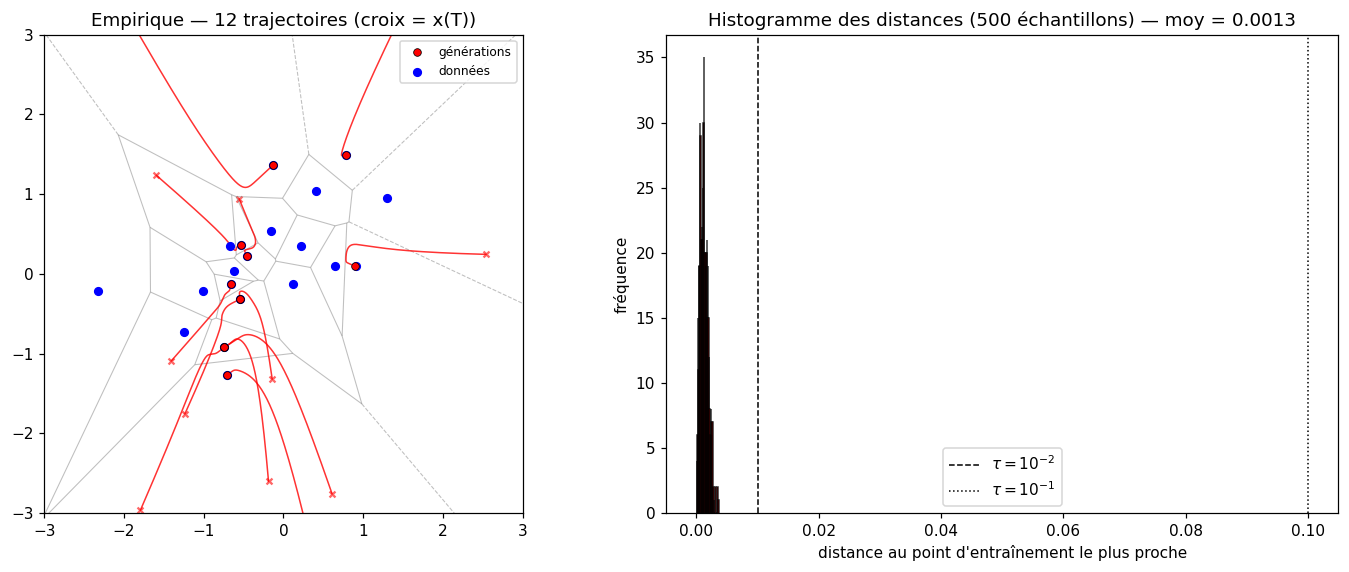

In [355]:
def xbar_empirique(y, sigma, Xd=None):
    Xd = X if Xd is None else Xd
    return softmax_rows(log_weights(y, sigma, Xd)) @ Xd

F_emp = lambda y, sigma: -(y - xbar_empirique(y, sigma))
evaluer("Empirique", F_emp, "red")

## 5. Estimateur 2 — score empirique explicite avec régularisation ridge (Tikhonov)

Stuart et al.  ajoutent à la perte le terme $\int \lambda(t)\,\mathbb E|s|^2_{\Gamma(t)}\,dt$. Le minimiseur est $(I + \Gamma(t))^{-1}\nabla \log p^N$ (Théorème 5.1). Avec le choix $\Gamma(t) = \frac{c}{\sigma^2(t)} I_d$, qui explose quand $t\to0$ :
$$s^N_{reg}(x,t) = -\frac{1}{c + \sigma^2(t)}\Big(x - \bar x^N(x,t)\Big)$$

En temps $s$ : $\dfrac{dy}{ds} = -\dfrac{\sigma^2}{\sigma^2 + c}\,(y - \bar y^N)$. Quand $\sigma^2 \ll c$, le champ s'éteint : la dynamique se fige avant d'avoir collapsé sur une donnée (interprétation de Stuart et al. : cela revient à arrêter le processus reverse à un temps positif). On prend $c = 10^{-2}$, valeur centrale de leur Figure 4.

[Ridge (c=0.01)]  entraînement :    0.00 s | génération :    0.30 s | total :    0.30 s
   distance moyenne : 0.10571 | médiane : 0.09981 | max : 0.30494
   taux de mémorisation : 0.4 % (tau=1e-2)  |  50.2 % (tau=1e-1)


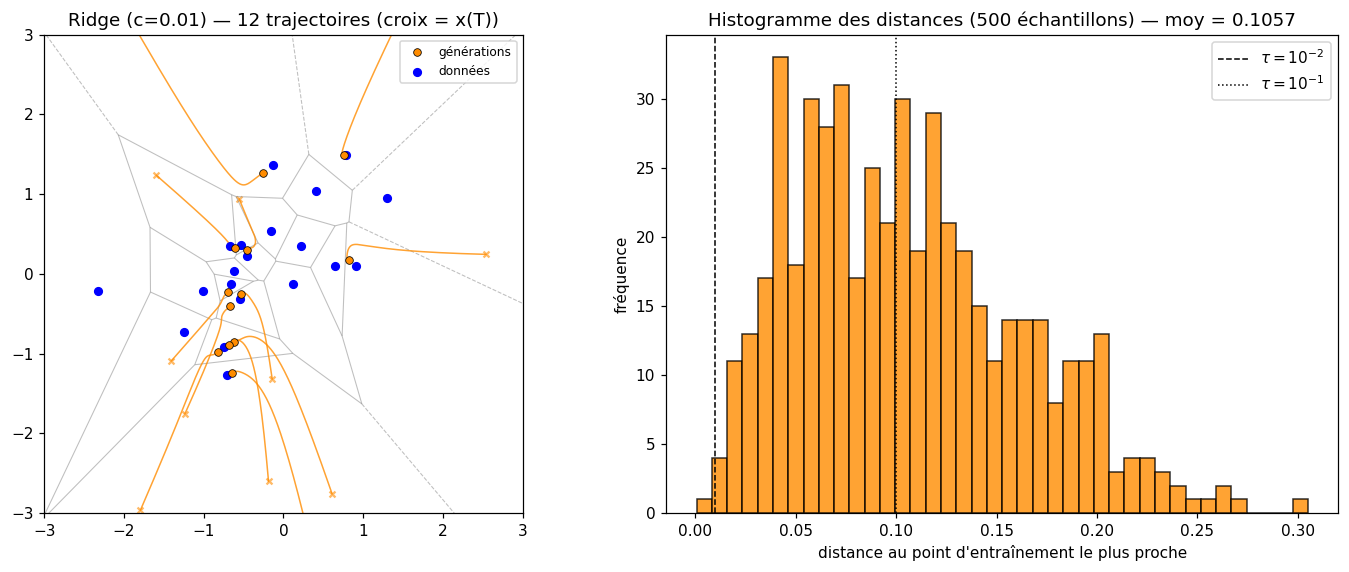

In [356]:
C_RIDGE = 1e-2
F_ridge = lambda y, sigma: -(sigma**2 / (sigma**2 + C_RIDGE)) * (y - xbar_empirique(y, sigma))
evaluer(f"Ridge (c={C_RIDGE})", F_ridge, "darkorange")

## 6. Estimateur 3 - score appris par un réseau de neurones

Même protocole que Stuart et al. (Section 5.3 et leur code) :

- **Réseau** : MLP ReLU de largeur 256 (3 couches cachées, comme dans leur code), avec 8 random Fourier features pour encoder le temps $t$.
- **Sortie** : le réseau donne directement le score $s_\theta(x, t)$.
- **Perte** : $J_0^N(\theta) = \mathbb E_{n,t,z} \left| \sigma(t)\, s_\theta(x_0^n + \sigma(t) z, t) + z \right|^2$, avec $t \sim \mathcal U([0, T])$ et $z \sim \mathcal N(0, I)$.
- **Entraînement** : Adam ($10^{-3}$), une époque = un pas sur les 20 données, $2 \times 10^5$ époques (`N_EPOCHS`), génération avec la moyenne mobile des poids (EMA).



In [357]:
class GaussianFourierProjection(nn.Module):
    #random Fourier features du temps (fréquences fixes, non apprises)
    def __init__(self, embed_dim=8, scale=1.0):
        super().__init__()
        self.register_buffer("W", torch.randn(embed_dim // 2) * scale)
    def forward(self, t):
        proj = t[:, None] * self.W[None, :] * 2 * np.pi
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=-1)

class ScoreNet(nn.Module):
    #identique à score_edm de Stuart et al. : Linear(2+8, w), puis depth couches (w, w), ReLU
    def __init__(self, width=256, depth=2, embed_dim=8):
        super().__init__()
        self.embed = GaussianFourierProjection(embed_dim, scale=1.0)
        layers = [nn.Linear(d + embed_dim, width), nn.ReLU()]
        for _ in range(depth):
            layers += [nn.Linear(width, width), nn.ReLU()]
        layers.append(nn.Linear(width, d))
        self.net = nn.Sequential(*layers)
    def forward(self, x, t):
        return self.net(torch.cat([x, self.embed(t)], dim=-1))     #sortie = score s_theta(x, t)

def sigma_de_t(t):
    return SIGMA_T * t / T                       #VE, g(t) = 10t : sigma(t) = sqrt(5) t

def perte(net, X0, c=0.0):
    #perte J_0^N (pondération sigma^2), + Tikhonov c|s|^2 si c > 0
    t = torch.rand(X0.shape[0])
    z = torch.randn_like(X0)
    std = sigma_de_t(t)[:, None]
    s = net(X0 + std * z, t)
    return (((std * s + z) ** 2).mean(1) + c * (s ** 2).mean(1)).mean()

def entrainer(c=0.0, n_epochs=200_000, width=256, seed=1, verbose=20_000, lr=1e-3, beta_ema=0.9999):
    torch.manual_seed(seed)
    net = ScoreNet(width=width)
    ema = copy.deepcopy(net)                     #moyenne mobile des poids, utilisée pour générer
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    Xt = torch.tensor(X, dtype=torch.float32)
    hist = []
    t0 = time.perf_counter()
    for epoch in range(n_epochs):                #1 époque = 1 pas itérations surr les N données
        loss = perte(net, Xt[torch.randperm(N)], c)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            for p_ema, p in zip(ema.parameters(), net.parameters()):
                p_ema.mul_(beta_ema).add_(p, alpha=1 - beta_ema)
        hist.append(loss.item())
        if verbose and (epoch % verbose == 0 or epoch == n_epochs - 1):
            print(f"  époque {epoch:7d}  perte = {np.mean(hist[-1000:]):.4f}")
    return ema, time.perf_counter() - t0, np.array(hist)

@torch.no_grad()
def predict(net, y, sigma):
    #score s_theta(y, t) en NumPy, avec t tel que sigma(t) = sigma
    t = torch.full((len(y),), sigma / SIGMA_T * T, dtype=torch.float32)
    return net(torch.tensor(y, dtype=torch.float32), t).numpy().astype(np.float64)

N_EPOCHS = 200_000

  époque       0  perte = 1.1940
  époque   20000  perte = 0.3662
  époque   40000  perte = 0.3510
  époque   60000  perte = 0.3449
  époque   80000  perte = 0.3426
  époque  100000  perte = 0.3437
  époque  120000  perte = 0.3360
  époque  140000  perte = 0.3340
  époque  160000  perte = 0.3326
  époque  180000  perte = 0.3311
  époque  199999  perte = 0.3228
temps d'entraînement : 168.5 s
[Réseau de neurones]  entraînement :  168.53 s | génération :    0.94 s | total :  169.47 s
   distance moyenne : 0.05423 | médiane : 0.04174 | max : 0.29512
   taux de mémorisation : 5.2 % (tau=1e-2)  |  86.0 % (tau=1e-1)


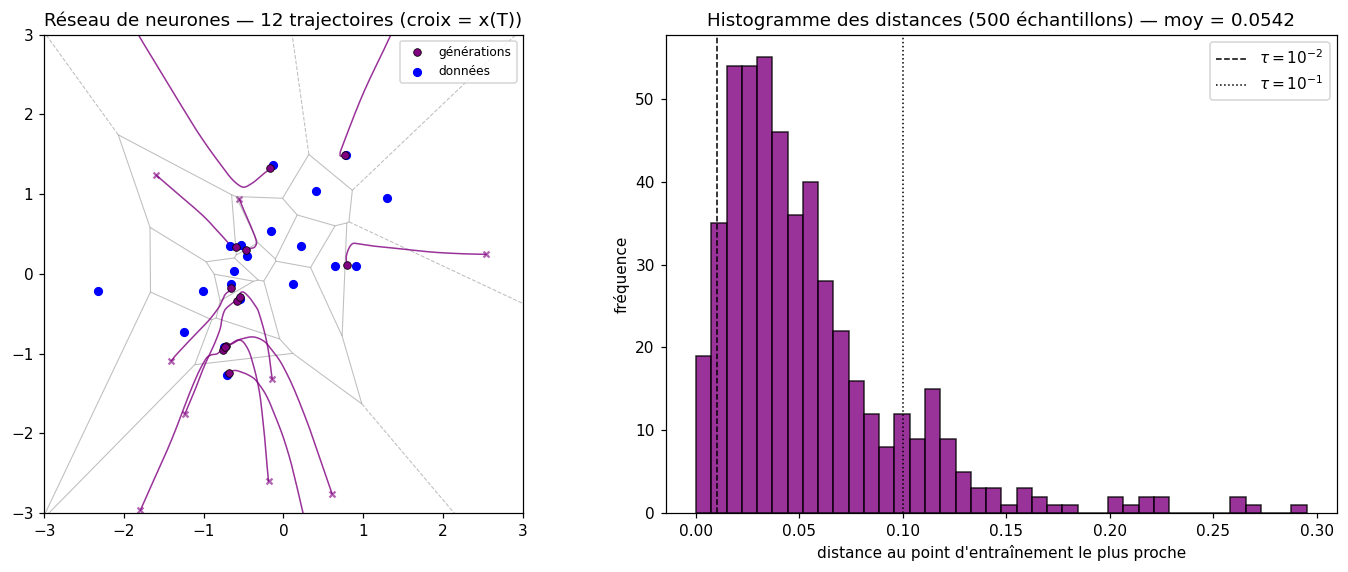

In [358]:
net_nn, t_train_nn, hist_nn = entrainer(c=0.0, n_epochs=N_EPOCHS)
print(f"temps d'entraînement : {t_train_nn:.1f} s")

#le réseau sort directement le score : dy/ds = sigma^2 * s_theta
F_nn = lambda y, sigma: sigma**2 * predict(net_nn, y, sigma)
evaluer("Réseau de neurones", F_nn, "purple", t_train=t_train_nn)

## 7. Estimateur 4 - réseau de neurones régularisé (perte de Tikhonov)

Même réseau, mais entraîné sur la perte régularisée $J^N_{reg,0}$ de Stuart et al. (Section 5.3) avec $\Gamma(t) = \frac{c}{\sigma^2} I$ :
$$\big|\sigma s + z\big|^2 + c\,|s|^2 = \big|\tilde s_\theta + z\big|^2 + \frac{c}{\sigma^2}\big|\tilde s_\theta\big|^2 $$
Son minimiseur est exactement le score ridge de la section 5 (via $\tilde s = \sigma s$).

**Remarque pratique** : le facteur $c/\sigma^2$ vaut jusqu'à $10^4$ pour $\sigma = 10^{-3}$ et déséquilibre complètement les gradients entre niveaux de bruit. Je multiplie donc la perte par $\sigma^2/(\sigma^2 + c)$ : c'est seulement un autre choix de la pondération $\lambda(t)$, qui **ne change pas le minimiseur** (la minimisation se fait point par point en $t$), mais rend l'entraînement stable. On garde $c = 10^{-2}$.

  époque       0  perte = 1.1940
  époque   20000  perte = 0.3816
  époque   40000  perte = 0.3719
  époque   60000  perte = 0.3686
  époque   80000  perte = 0.3715
  époque  100000  perte = 0.3727
  époque  120000  perte = 0.3680
  époque  140000  perte = 0.3638
  époque  160000  perte = 0.3654
  époque  180000  perte = 0.3643
  époque  199999  perte = 0.3577
temps d'entraînement : 158.8 s
[Réseau régularisé (c=0.01)]  entraînement :  158.80 s | génération :    0.94 s | total :  159.74 s
   distance moyenne : 0.13283 | médiane : 0.11821 | max : 0.67837
   taux de mémorisation : 0.4 % (tau=1e-2)  |  43.0 % (tau=1e-1)


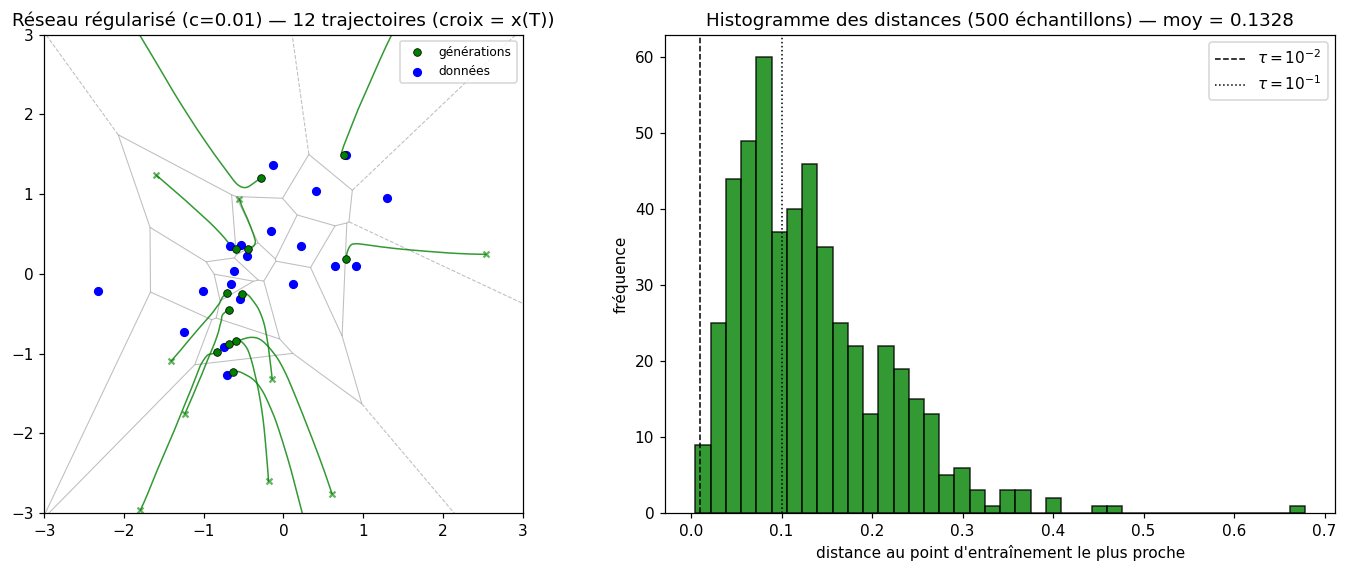

In [359]:
C_NN = 1e-2
net_nnreg, t_train_nnreg, hist_nnreg = entrainer(c=C_NN, n_epochs=N_EPOCHS)
print(f"temps d'entraînement : {t_train_nnreg:.1f} s")

F_nnreg = lambda y, sigma: sigma**2 * predict(net_nnreg, y, sigma)
evaluer(f"Réseau régularisé (c={C_NN})", F_nnreg, "green", t_train=t_train_nnreg)

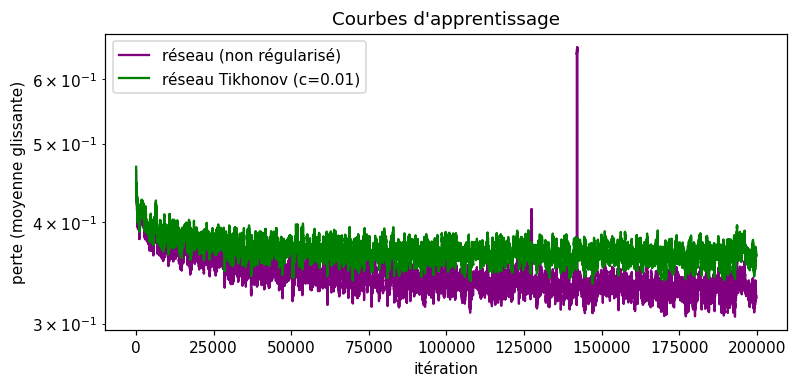

In [360]:
fig, ax = plt.subplots(figsize=(8, 3.5))
lis = lambda h: np.convolve(h, np.ones(200) / 200, mode="valid")
ax.plot(lis(hist_nn), label="réseau (non régularisé)", c="purple")
ax.plot(lis(hist_nnreg), label=f"réseau Tikhonov (c={C_NN})", c="green")
ax.set_xlabel("itération"); ax.set_ylabel("perte (moyenne glissante)"); ax.set_yscale("log")
ax.set_title("Courbes d'apprentissage"); ax.legend(); plt.show()

## Complément - effet de la largeur et du nombre d'époques

Stuart et al. montrent que deux régularisations implicites limitent la mémorisation des réseaux : un réseau plus petit (Figures 10-11, à $2 \times 10^5$ époques) et un entraînement plus court (Figures 8-9, à largeur 256). On reproduit ces deux expériences, en faisant varier un seul paramètre à la fois.

--- largeur 8 ---
  époque       0  perte = 1.0652
  époque   20000  perte = 0.3960
  époque   40000  perte = 0.4041
  époque   60000  perte = 0.4007
  époque   80000  perte = 0.4016
  époque  100000  perte = 0.3933
  époque  120000  perte = 0.3878
  époque  140000  perte = 0.3936
  époque  160000  perte = 0.3961
  époque  180000  perte = 0.3872
  époque  199999  perte = 0.3968
temps d'entraînement : 59.5 s
[Réseau (largeur 8)]  entraînement :   59.48 s | génération :    0.12 s | total :   59.60 s
   distance moyenne : 0.25490 | médiane : 0.23540 | max : 0.98970
   taux de mémorisation : 0.0 % (tau=1e-2)  |  15.0 % (tau=1e-1)


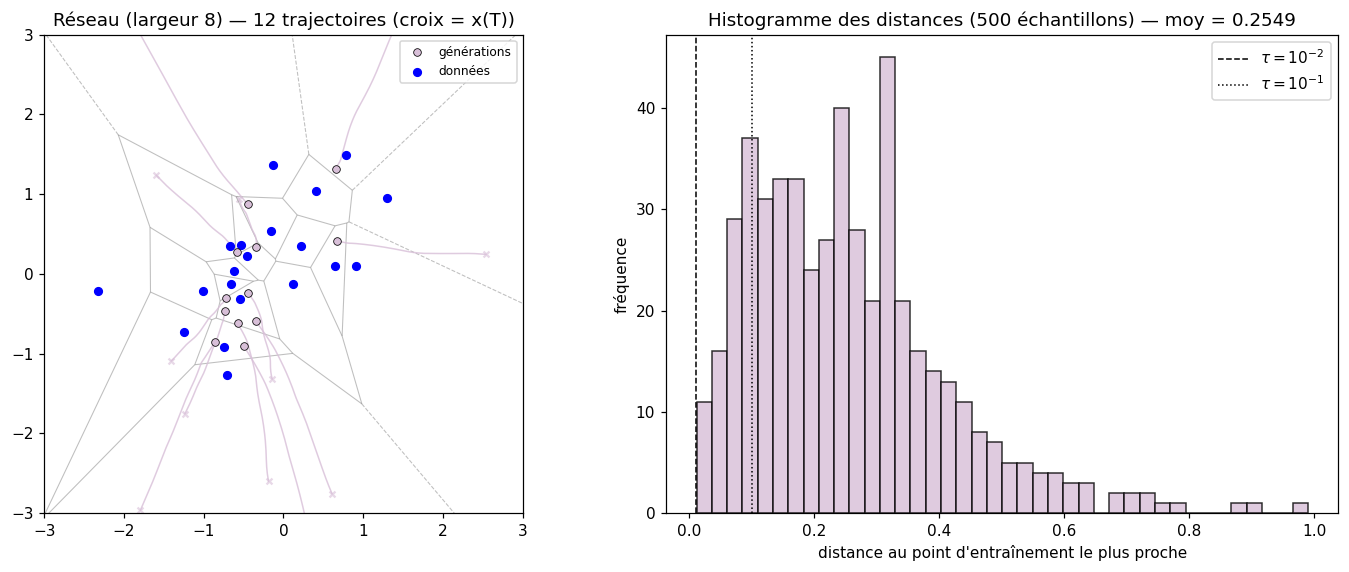

--- largeur 32 ---
  époque       0  perte = 1.0139
  époque   20000  perte = 0.3795
  époque   40000  perte = 0.3753
  époque   60000  perte = 0.3682
  époque   80000  perte = 0.3715
  époque  100000  perte = 0.3652
  époque  120000  perte = 0.3640
  époque  140000  perte = 0.3582
  époque  160000  perte = 0.3670
  époque  180000  perte = 0.3524
  époque  199999  perte = 0.3559
temps d'entraînement : 62.6 s
[Réseau (largeur 32)]  entraînement :   62.61 s | génération :    0.16 s | total :   62.77 s
   distance moyenne : 0.14845 | médiane : 0.12591 | max : 0.62824
   taux de mémorisation : 1.0 % (tau=1e-2)  |  37.4 % (tau=1e-1)


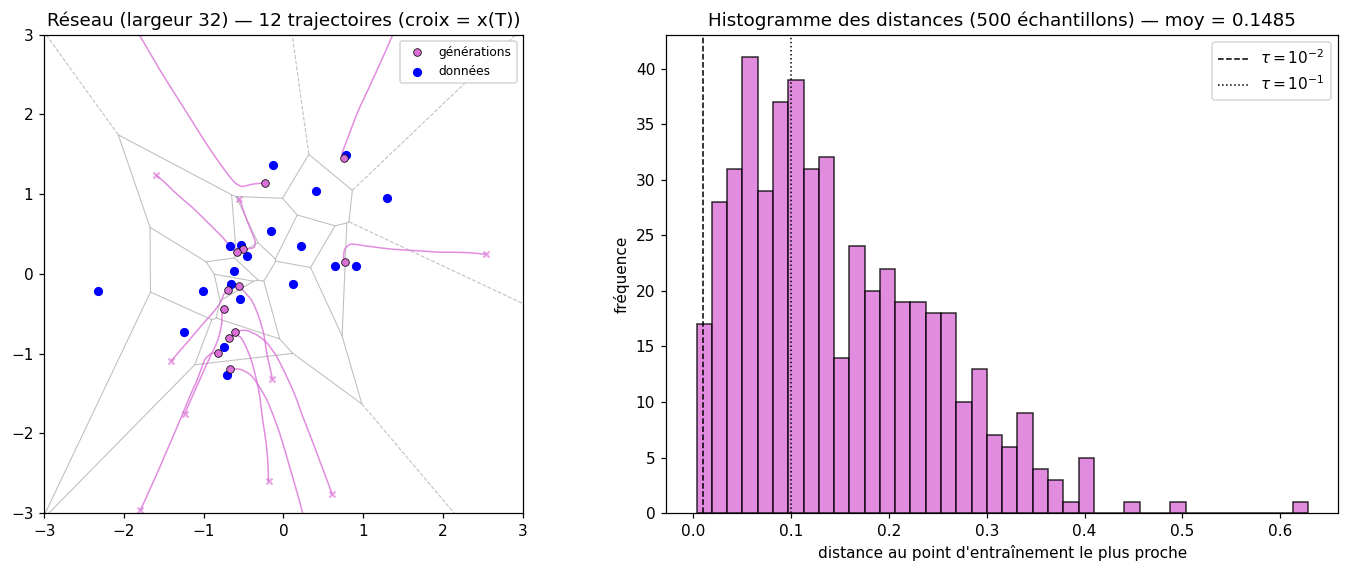

--- largeur 128 ---
  époque       0  perte = 1.0860
  époque   20000  perte = 0.3688
  époque   40000  perte = 0.3569
  époque   60000  perte = 0.3483
  époque   80000  perte = 0.3467
  époque  100000  perte = 0.3380
  époque  120000  perte = 0.3392
  époque  140000  perte = 0.3368
  époque  160000  perte = 0.3332
  époque  180000  perte = 0.3311
  époque  199999  perte = 0.3302
temps d'entraînement : 89.0 s
[Réseau (largeur 128)]  entraînement :   88.98 s | génération :    0.45 s | total :   89.43 s
   distance moyenne : 0.06108 | médiane : 0.04691 | max : 0.53197
   taux de mémorisation : 5.0 % (tau=1e-2)  |  84.4 % (tau=1e-1)


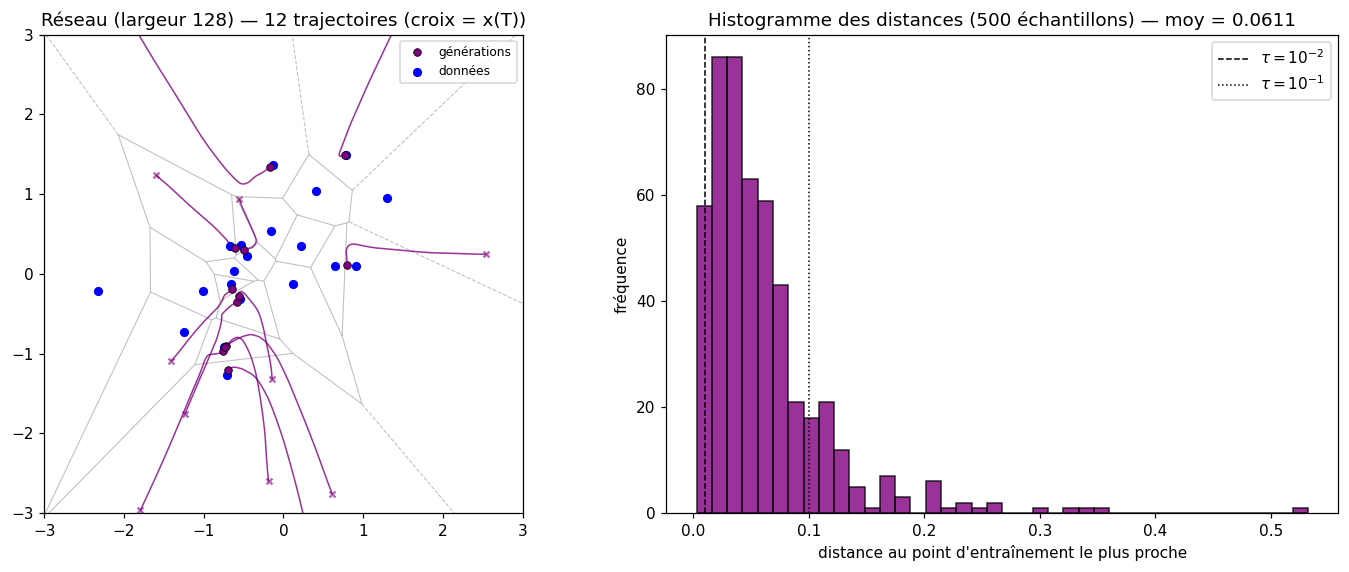

In [361]:
for w, coul in zip([8, 32, 128], ["thistle", "orchid", "purple"]):
    print(f"--- largeur {w} ---")
    net_w, t_w, _ = entrainer(c=0.0, n_epochs=N_EPOCHS, width=w, verbose=N_EPOCHS // 10)
    print(f"temps d'entraînement : {t_w:.1f} s")
    F_w = lambda y, sigma, net=net_w: sigma**2 * predict(net, y, sigma)
    evaluer(f"Réseau (largeur {w})", F_w, coul, t_train=t_w)

--- 5000 époques ---
  époque       0  perte = 1.1940
  époque    1000  perte = 0.4214
  époque    2000  perte = 0.4012
  époque    3000  perte = 0.4016
  époque    4000  perte = 0.3901
  époque    4999  perte = 0.3835
temps d'entraînement : 4.4 s
[Réseau (5000 époques)]  entraînement :    4.36 s | génération :    1.06 s | total :    5.42 s
   distance moyenne : 0.23983 | médiane : 0.22201 | max : 1.10206
   taux de mémorisation : 0.2 % (tau=1e-2)  |  16.6 % (tau=1e-1)


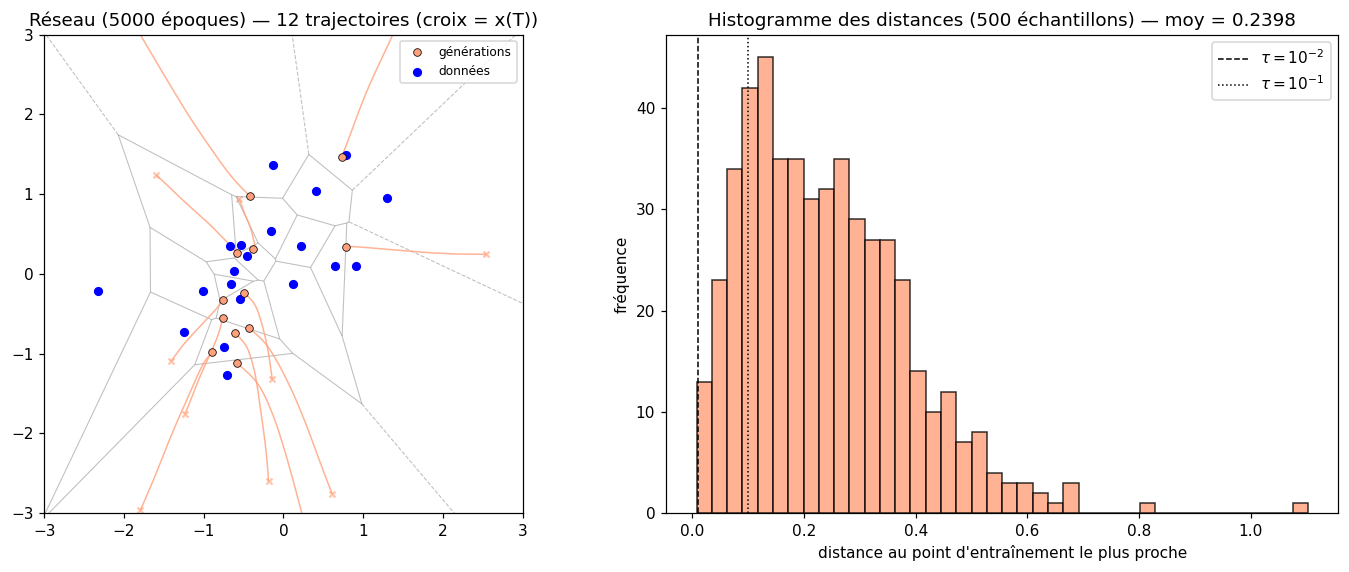

--- 20000 époques ---
  époque       0  perte = 1.1940
  époque    4000  perte = 0.3901
  époque    8000  perte = 0.3760
  époque   12000  perte = 0.3709
  époque   16000  perte = 0.3714
  époque   19999  perte = 0.3660
temps d'entraînement : 16.2 s
[Réseau (20000 époques)]  entraînement :   16.21 s | génération :    0.99 s | total :   17.20 s
   distance moyenne : 0.16504 | médiane : 0.13985 | max : 0.54545
   taux de mémorisation : 0.4 % (tau=1e-2)  |  33.4 % (tau=1e-1)


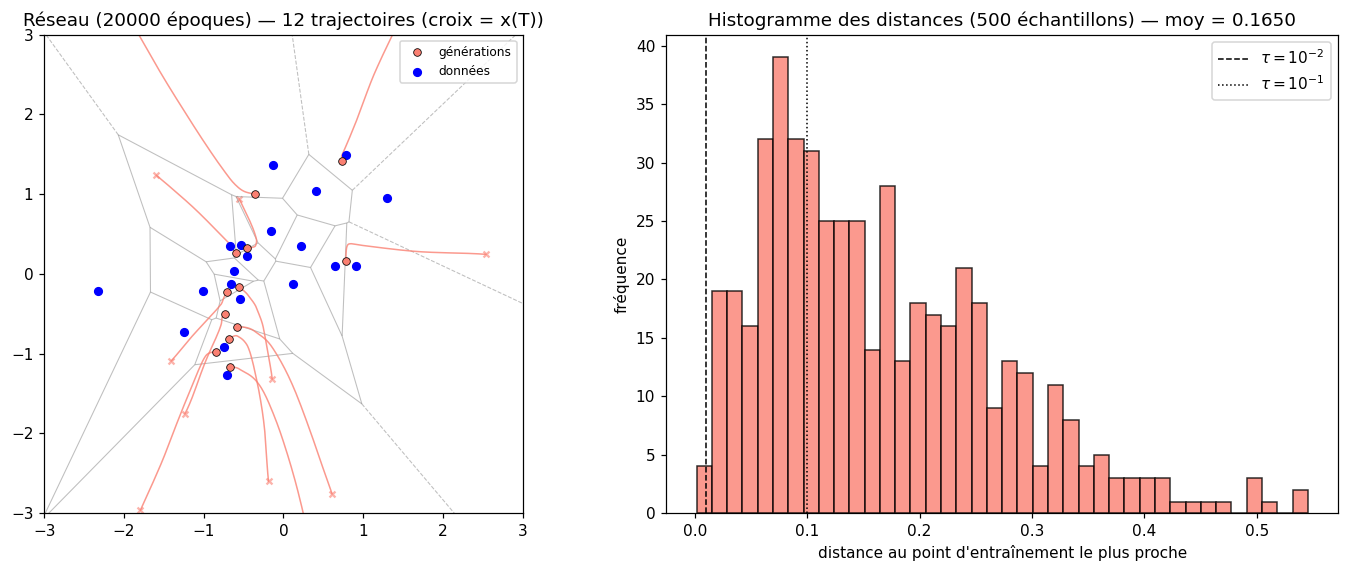

--- 50000 époques ---
  époque       0  perte = 1.1940
  époque   10000  perte = 0.3765
  époque   20000  perte = 0.3662
  époque   30000  perte = 0.3568
  époque   40000  perte = 0.3510
  époque   49999  perte = 0.3496
temps d'entraînement : 42.3 s
[Réseau (50000 époques)]  entraînement :   42.35 s | génération :    1.01 s | total :   43.36 s
   distance moyenne : 0.11236 | médiane : 0.09135 | max : 0.41935
   taux de mémorisation : 1.4 % (tau=1e-2)  |  55.0 % (tau=1e-1)


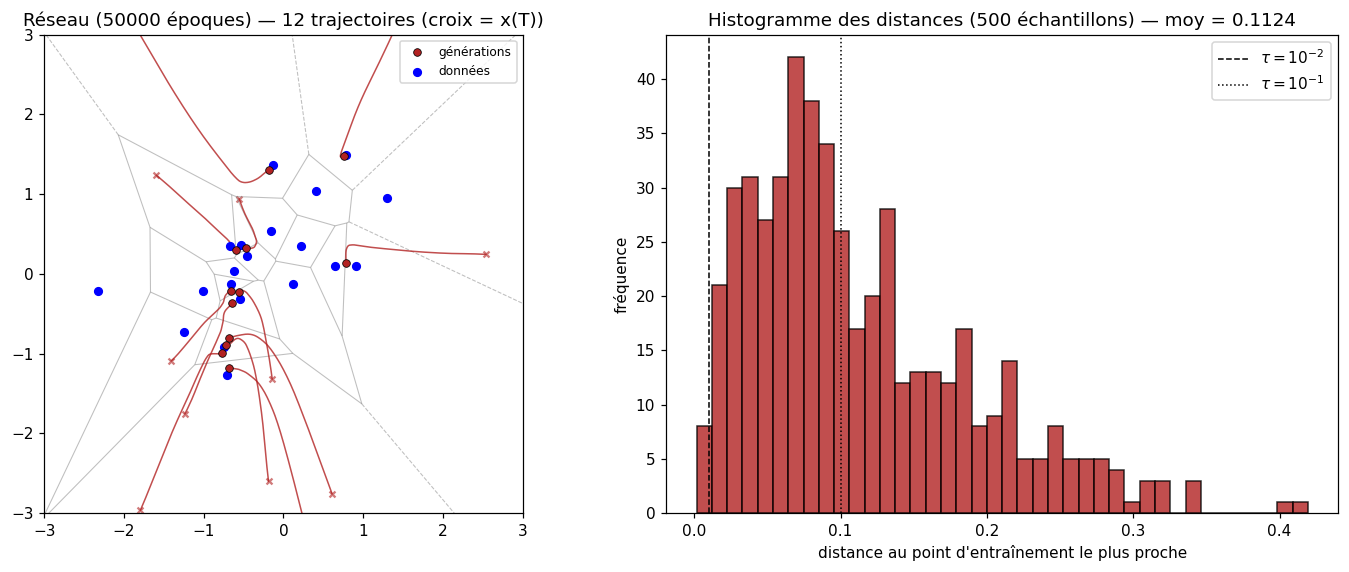

In [362]:
# Effet du nombre d'époques (largeur 256 fixée), cf. Figures 8-9 de Stuart et al.
for n_ep, coul in zip([5_000, 20_000, 50_000], ["lightsalmon", "salmon", "firebrick"]):
    print(f"--- {n_ep} époques ---")
    net_e, t_e, _ = entrainer(c=0.0, n_epochs=n_ep, width=256,
                              verbose=n_ep // 5, beta_ema=0.999)
    print(f"temps d'entraînement : {t_e:.1f} s")
    F_e = lambda y, sigma, net=net_e: sigma**2 * predict(net, y, sigma)
    evaluer(f"Réseau ({n_ep} époques)", F_e, coul, t_train=t_e)

## 8. Estimateur 5 - score par validation croisée Leave-One-Out (explicite)

On a :
$$s^{LOO}(x,t) = \frac1N\sum_{k=1}^N \nabla_x\log p^{D_{-k}}(x,t) = -\frac{1}{\sigma^2(t)}\Big(x - \bar x^{LOO}(x,t)\Big) \qquad \bar x^{LOO} = \frac1N\sum_{k=1}^N\sum_{j\neq k} w^{D_{-k}}_j(x,t)\,x^j_0 $$

En temps $s$ : $\dfrac{dy}{ds} = -(y - \bar y^{LOO})$. 

### 8.a Version naïve - $O(N^2)$

On suit littéralement la définition : pour chaque $k$, on reconstruit le mélange sur $D_{-k}$ (softmax sur $N-1$ poids), on calcule son barycentre, puis on moyenne les $N$ barycentres. Coût : $N$ sous-problèmes de taille $N-1$ par particule, soit $O(N^2)$.

[CV-LOO naïf O(N²)]  entraînement :    0.00 s | génération :    1.66 s | total :    1.66 s
   distance moyenne : 0.01871 | médiane : 0.01690 | max : 0.06173
   taux de mémorisation : 27.4 % (tau=1e-2)  |  100.0 % (tau=1e-1)


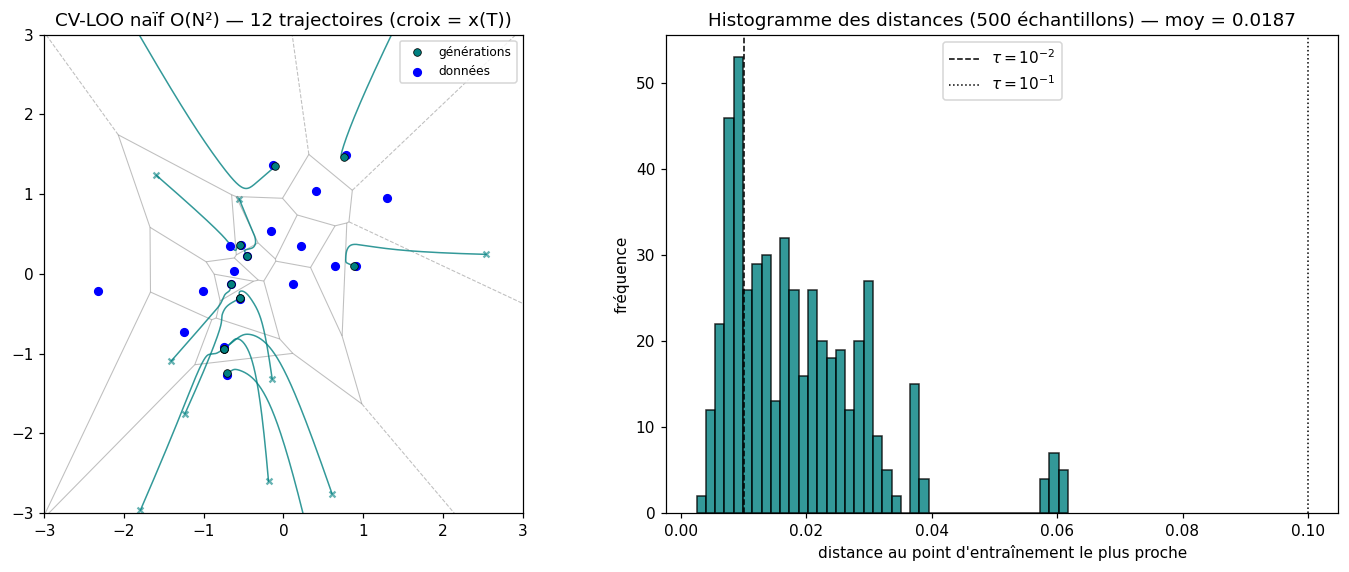

In [363]:
def xbar_loo_naif(y, sigma, Xd=None):
    Xd = X if Xd is None else Xd
    Nd = len(Xd)
    l = log_weights(y, sigma, Xd)
    acc = np.zeros_like(y)
    for k in range(Nd):                         #N ensembles D_{-k}
        masque = np.ones(Nd, dtype=bool); masque[k] = False
        acc += softmax_rows(l[:, masque]) @ Xd[masque]   # barycentre de p^{D_{-k}}
    return acc / Nd

F_loo_naif = lambda y, sigma: -(y - xbar_loo_naif(y, sigma))
evaluer("CV-LOO naïf O(N²)", F_loo_naif, "teal")

### 8.b Version optimisée - $O(N)$ 

On calcule une seule fois $S = \sum_j \tilde w_j$ et $A = \sum_j \tilde w_j x^j_0 = S\,\bar x^D$, puis chaque terme vaut
$$\bar x^{D_{-k}} = \frac{A - \tilde w_k x^k_0}{S - \tilde w_k}$$
d'où $O(1)$ par $k$ et $O(N)$ au total

**Point numérique important (non traité dans le mémoire) :** près d'une donnée et pour $\sigma$ petit, le poids du point le plus proche $k^\star$ vaut $\tilde w_{k^\star} \approx S$. La soustraction $S - \tilde w_{k^\star}$ subit alors une **annulation catastrophique** : en flottant on obtient $0$ ou du bruit, alors que la vraie valeur (la somme des autres poids, qui peut valoir $10^{-300}$ relativement) est précisément celle qui porte l'effet LOO. Or c'est exactement le régime $t\to0$ qui nous intéresse.

Correctif, qui garde un coût $O(N)$ :
- pour $k \neq k^\star$ : $S - \tilde w_k \geq \tilde w_{k^\star}$, pas d'annulation, on garde la formule ;
- pour $k = k^\star$ uniquement : on recalcule directement la somme sur $j\neq k^\star$ en log-sum-exp, avec le **deuxième** plus grand log-poids comme décalage (un seul passage supplémentaire en $O(N)$).

sigma =   1e+00  |  écart max naïf / rapide = 1.78e-15
sigma =   1e-01  |  écart max naïf / rapide = 1.78e-15
sigma =   1e-02  |  écart max naïf / rapide = 1.11e-16
sigma =   1e-03  |  écart max naïf / rapide = 0.00e+00
[CV-LOO rapide O(N)]  entraînement :    0.00 s | génération :    0.67 s | total :    0.67 s
   distance moyenne : 0.01871 | médiane : 0.01690 | max : 0.06173
   taux de mémorisation : 27.4 % (tau=1e-2)  |  100.0 % (tau=1e-1)


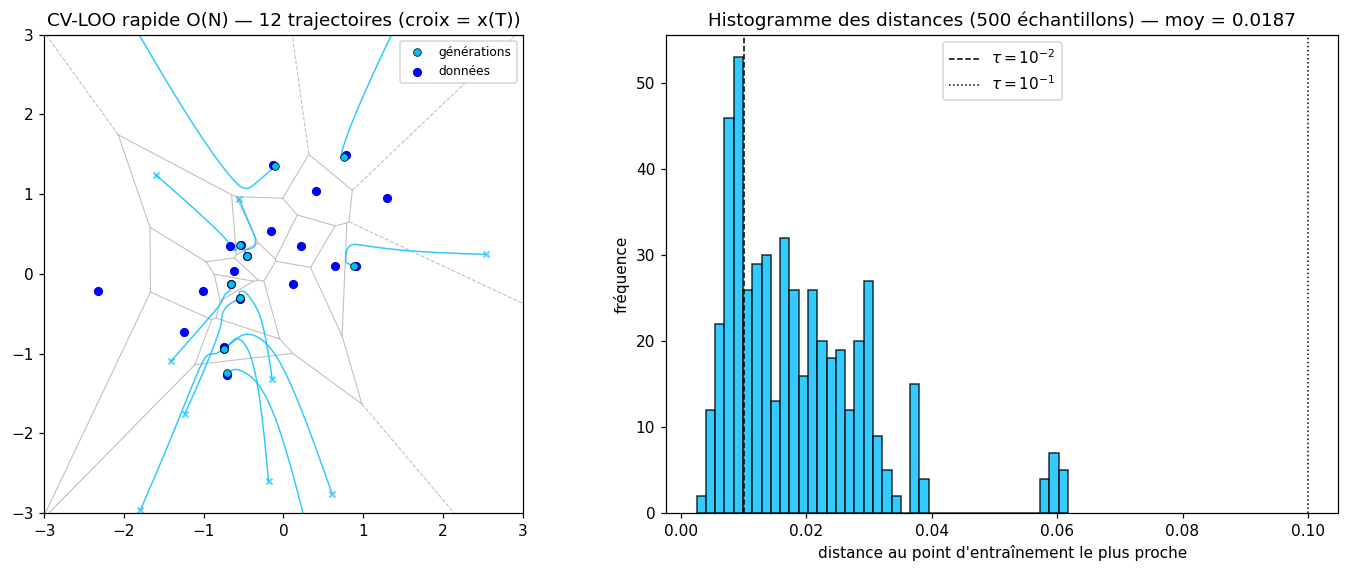

In [364]:
def xbar_loo_rapide(y, sigma, Xd=None):
    Xd = X if Xd is None else Xd
    l = log_weights(y, sigma, Xd)
    P, ar = len(y), np.arange(len(y))
    k1 = l.argmax(1)                              #point dominant k*
    E = np.exp(l - l[ar, k1][:, None])            #poids décalés (max = 1)
    S = E.sum(1)                                  #somme globale        
    A = E @ Xd                                    # S * xbar^D          
    num = A[:, None, :] - E[:, :, None] * Xd[None]   # A - w_k x_k       (500, N, d)
    den = S[:, None] - E                             # S - w_k           (500, N)
    den[ar, k1] = 1.0                             #évite 0/0 (valeur écrasée ensuite)
    xb = num / den[:, :, None]
    #correction stable pour k = k* : log-sum-exp avec le 2e plus grand log-poids
    l2 = l.copy(); l2[ar, k1] = -np.inf
    E2 = np.exp(l2 - l2.max(1, keepdims=True))
    xb[ar, k1] = (E2 @ Xd) / E2.sum(1, keepdims=True)
    return xb.mean(1)

#vérification : les deux versions calculent la même chose
yt = np.vstack([np.random.default_rng(1).standard_normal((200, d)) * 2, X + 1e-4])
for sg in [1.0, 1e-1, 1e-2, 1e-3]:
    ecart = np.abs(xbar_loo_naif(yt, sg) - xbar_loo_rapide(yt, sg)).max()
    print(f"sigma = {sg:7.0e}  |  écart max naïf / rapide = {ecart:.2e}")

F_loo_rapide = lambda y, sigma: -(y - xbar_loo_rapide(y, sigma))
evaluer("CV-LOO rapide O(N)", F_loo_rapide, "deepskyblue")

## 9. CV K-fold ($K = 5$)

Section 9 du mémoire : partition aléatoire en $K$ blocs $T_k$ de taille $N/K = 4$, $L_k = D\setminus T_k$
$$\bar x^{KF} = \frac1K\sum_{k=1}^K \sum_{j\notin T_k} w^{L_k}_j x^j_0 $$
- naïvement : on recalcule chaque mélange $p^{L_k}$, coût $O(KN)$ 

[CV-5-fold O(KN)]  entraînement :    0.00 s | génération :    0.52 s | total :    0.52 s
   distance moyenne : 0.08488 | médiane : 0.08235 | max : 0.26391
   taux de mémorisation : 0.0 % (tau=1e-2)  |  64.8 % (tau=1e-1)


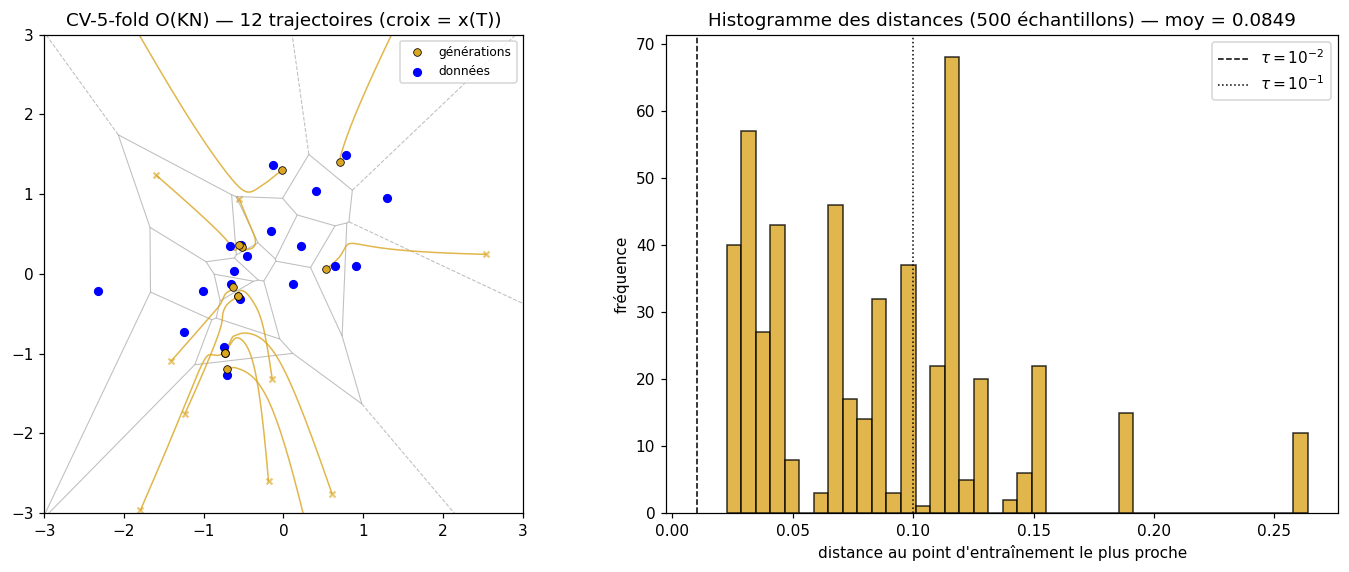

In [365]:
K = 5
FOLD = np.random.default_rng(3).permutation(np.arange(N) % K)     # étiquette de bloc de chaque point

def xbar_kf(y, sigma, Xd=None, fold=None, Kf=K):
    Xd = X if Xd is None else Xd; fold = FOLD if fold is None else fold
    l = log_weights(y, sigma, Xd); acc = np.zeros_like(y)
    for k in range(Kf):
        m = fold != k                                          # L_k = D \ T_k
        acc += softmax_rows(l[:, m]) @ Xd[m]                   # barycentre de p^{L_k}
    return acc / Kf

evaluer(f"CV-{K}-fold O(KN)", lambda y, s: -(y - xbar_kf(y, s)), "goldenrod")

## Synthèse(temps et mémorisation)

In [366]:
df = pd.DataFrame(RESULTS).T
tab = pd.DataFrame({
    "entraînement (s)": df.t_train.round(2),
    "génération (s)": df.t_gen.round(2),
    "total (s)": df.t_total.round(2),
    "distance moyenne": df.dist_moy.map("{:.4f}".format),
    "distance max": df.dist_max.map("{:.4f}".format),
    "mémorisation τ=1e-2": (100 * df.taux_1e2).map("{:.1f} %".format),
    "mémorisation τ=1e-1": (100 * df.taux_1e1).map("{:.1f} %".format),
})
tab

,entraînement (s),génération (s),total (s),distance moyenne,distance max,mémorisation τ=1e-2,mémorisation τ=1e-1
Empirique,0.00,0.29,0.29,0.0013,0.0037,100.0 %,100.0 %
Ridge (c=0.01),0.00,0.30,0.30,0.1057,0.3049,0.4 %,50.2 %
Réseau de neurones,168.53,0.94,169.47,0.0542,0.2951,5.2 %,86.0 %
Réseau régularisé (c=0.01),158.80,0.94,159.74,0.1328,0.6784,0.4 %,43.0 %
Réseau (largeur 8),59.48,0.12,59.60,0.2549,0.9897,0.0 %,15.0 %
Réseau (largeur 32),62.61,0.16,62.77,0.1485,0.6282,1.0 %,37.4 %
Réseau (largeur 128),88.98,0.45,89.43,0.0611,0.5320,5.0 %,84.4 %
Réseau (5000 époques),4.36,1.06,5.42,0.2398,1.1021,0.2 %,16.6 %
Réseau (20000 époques),16.21,0.99,17.20,0.1650,0.5454,0.4 %,33.4 %
Réseau (50000 époques),42.35,1.01,43.36,0.1124,0.4194,1.4 %,55.0 %
